# Modelado de series temporales con scikit-learn y PyTorch

En este notebook prepararemos una serie temporal, estableceremos modelos de referencia y evaluaremos modelos de aprendizaje automático.

## 1. Preparación del entorno

Importamos las librerías necesarias:

- **json:** lectura y escritura de datos en formato JSON.
- **NumPy y pandas:** operaciones numéricas y organización de datos.
- **Matplotlib y Seaborn:** visualización y carga de datos.
- **scikit-learn:** regresión lineal y redes neuronales con `MLPRegressor`.
- **PyTorch:** construcción y entrenamiento de redes neuronales mediante `torch.nn`.

Configuramos PyTorch para utilizar un solo hilo de CPU y algoritmos deterministas. Esto ayuda a controlar la variabilidad de ejecución, aunque también necesitaremos fijar las semillas aleatorias al crear los modelos.

Finalmente, mostramos las versiones de PyTorch y scikit-learn para documentar el entorno.

In [2]:
#! pip install torch

In [3]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch

from torch import nn
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

# Configuración para favorecer la reproducibilidad en CPU
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

# Tamaño predeterminado de las gráficas
plt.rcParams['figure.figsize'] = (10, 4)

# Versiones del entorno
print(
    'torch', torch.__version__,
    '| sklearn', sklearn.__version__
)

torch 2.14.1 | sklearn 1.6.1


## 2. Datos, separación temporal, métricas y modelos de referencia

Retomaremos la serie mensual de pasajeros del notebook anterior y conservaremos la misma separación:

- **Entrenamiento:** enero de 1949 a diciembre de 1958.
- **Prueba:** enero de 1959 a diciembre de 1960.

Evaluaremos los pronósticos mediante **RMSE** y **MAPE**.

Utilizaremos dos referencias para valorar el desempeño de los siguientes modelos:

| Modelo de referencia | RMSE obtenido en el notebook anterior |
|---|---:|
| Estacional ingenuo | 77.0 |
| Regresión lineal AR(13) sobre la serie transformada | 67.6 |

El RMSE se expresa en miles de pasajeros. Al reproducir los mismos datos y procedimientos, esperamos obtener resultados equivalentes, salvo posibles diferencias numéricas del entorno.

In [4]:
# Carga de los 144 registros mensuales: enero de 1949 a diciembre de 1960
flights = sns.load_dataset('flights')

y = pd.Series(
    flights['passengers'].values,
    index=pd.date_range(
        '1949-01-01',
        periods=144,
        freq='MS'
    ),
    name='passengers'
)

# Verificación de los datos
assert len(y) == 144 and y.sum() == 40363

# Separación cronológica
train, test = y[:'1958'], y['1959':]

# Horizonte: 24 meses, pronosticados desde diciembre de 1958
H = len(test)


def rmse(f, a):
    f = np.asarray(f, float)
    a = np.asarray(a, float)
    return float(np.sqrt(np.mean((f - a) ** 2)))


def mape(f, a):
    f = np.asarray(f, float)
    a = np.asarray(a, float)
    return float(100 * np.mean(np.abs((f - a) / a)))


results = {}

# Modelo estacional ingenuo: repetir 1958 para 1959 y 1960
snaive = np.tile(train.values[-12:], 2)

results['Seasonal naive'] = (
    rmse(snaive, test),
    mape(snaive, test)
)

### Preparación de los datos y primera referencia

Construimos una serie de **144 observaciones mensuales**, expresadas en miles de pasajeros. El índice usa la frecuencia `MS`, que asigna cada observación al primer día de su mes.

La instrucción `assert` comprueba que la longitud y la suma de los datos coincidan con los valores esperados.

La separación temporal deja:

| Conjunto | Periodo | Observaciones |
|---|---|---:|
| Entrenamiento | Enero de 1949 a diciembre de 1958 | 120 |
| Prueba | Enero de 1959 a diciembre de 1960 | 24 |

Las funciones `rmse` y `mape` comparan los pronósticos con los valores reales. El RMSE se expresa en miles de pasajeros y el MAPE en porcentaje. En ambos casos, un valor menor indica menor error.

Como primera referencia, el modelo **estacional ingenuo** repite los 12 valores de 1958 durante los dos años de prueba. Así conserva el patrón mensual de ese año, pero no incorpora crecimiento adicional.

Sus métricas quedan guardadas en `results['Seasonal naive']`. Este bloque no imprime resultados; únicamente prepara los datos y almacena la evaluación.

## 4. Transformación, estandarización y referencia sin aprendizaje

Aplicamos el logaritmo a los pasajeros y seleccionamos únicamente el periodo de entrenamiento. Después usamos `z_of` para calcular las diferencias mensual y estacional.

La transformación reduce las 120 observaciones de entrenamiento a **107 valores**, correspondientes a febrero de 1950 a diciembre de 1958.

Estandarizamos esos valores utilizando su media y desviación estándar:

$$
u_t=\frac{z_t-m_z}{s_z}
$$

Con ventanas de **13 valores anteriores**, construimos 94 ejemplos para entrenar los modelos posteriores.

### Referencia basada en la media

Antes de entrenar un modelo, pronosticamos que todos los valores futuros de la serie transformada serán iguales a su media de entrenamiento:

$$
\widehat{z}_{T+h}=m_z
$$

Reconstruimos los logaritmos con `undo` y aplicamos la exponencial para obtener pasajeros.

Esta referencia permite evaluar qué desempeño obtenemos con la transformación y una predicción constante, sin entrenar una regresión o una red neuronal.

In [5]:
def make_windows(s, p):
    s = np.asarray(s, float)
    X = np.array([
        s[i - p:i] for i in range(p, len(s))
    ])
    return X, s[p:]


def recursive_forecast(model, history, p, h):
    hist = list(np.asarray(history, float))
    out = []

    for _ in range(h):
        nxt = float(
            model.predict(
                np.array(hist[-p:]).reshape(1, -1)
            )[0]
        )
        out.append(nxt)
        hist.append(nxt)

    return np.array(out)


def z_of(Lser):
    Lser = np.asarray(Lser, float)
    return (
        Lser[13:]
        - Lser[12:-1]
        - Lser[1:-12]
        + Lser[:-13]
    )


def undo(z_future, L_hist):
    Lh = list(L_hist)

    for zt in z_future:
        Lh.append(
            zt + Lh[-1] + Lh[-12] - Lh[-13]
        )

    return np.array(Lh[len(L_hist):])


# 1. Preparar la serie transformada
p = 13
H = len(test)

L = np.log(y.values)
Ltr = L[:len(train)]

# 107 valores transformados del entrenamiento
ztr = z_of(Ltr)

# Estandarización usando solamente el entrenamiento
mz, sz = ztr.mean(), ztr.std()

# 94 ventanas de 13 rezagos
Xz, tz = make_windows((ztr - mz) / sz, p)


# 2. Referencia estacional ingenua
snaive = np.tile(
    train.values[-12:],
    int(np.ceil(H / 12))
)[:H]

results['Seasonal naive'] = (
    rmse(snaive, test),
    mape(snaive, test)
)


# 3. Referencia sin aprendizaje: media de la serie transformada
f_zmean = np.exp(
    undo(np.full(H, mz), Ltr)
)

results['Transform, no learning'] = (
    rmse(f_zmean, test),
    mape(f_zmean, test)
)


# 4. Regresión lineal sobre la serie transformada
lin = LinearRegression().fit(Xz, tz)

zf_lin = recursive_forecast(
    lin, (ztr - mz) / sz, p, H
) * sz + mz

f_lin = np.exp(undo(zf_lin, Ltr))

results['Linear AR(13)'] = (
    rmse(f_lin, test),
    mape(f_lin, test)
)


# 5. Mostrar resultados
print('Ventanas de entrenamiento:', Xz.shape)

for k, (r, m) in results.items():
    print(f'{k:31s} RMSE {r:6.1f}  MAPE {m:5.1f}%')


# 6. Verificar los RMSE de referencia
assert (
    abs(results['Seasonal naive'][0] - 77.0) < 0.05
    and abs(results['Linear AR(13)'][0] - 67.6) < 0.05
), 'Los RMSE no coinciden con las referencias esperadas.'

Ventanas de entrenamiento: (94, 13)
Seasonal naive                  RMSE   77.0  MAPE  15.5%
Transform, no learning          RMSE   76.8  MAPE  15.4%
Linear AR(13)                   RMSE   67.6  MAPE  13.2%


## De una tabla a secuencias

Preparamos las ventanas temporales para utilizarlas en una red recurrente.

Hasta ahora, `Xz` tiene forma **(94, 13)**: contiene 94 ventanas con 13 valores anteriores cada una, ordenados del más antiguo al más reciente.

Para una red recurrente de PyTorch configurada con `batch_first=True`, organizamos las entradas en tres dimensiones:

**(número de ventanas, pasos temporales, características por paso)**

En este caso, la forma será **(94, 13, 1)**. Cada ventana contiene 13 pasos temporales y en cada paso observamos una sola característica: el valor de la serie transformada y estandarizada.

Definimos dos funciones:

- **`to_seq(X)`:** convierte las entradas en un tensor de tipo `float32` y agrega la dimensión de características.
- **`to_target(t)`:** convierte los valores objetivo en un tensor de tipo `float32`, conservando su forma.

In [6]:
def to_seq(X):
    # Tabla (n, 13) → tensor de secuencias (n, 13, 1)
    return torch.tensor(
        np.asarray(X, float),
        dtype=torch.float32
    ).unsqueeze(-1)


def to_target(t):
    return torch.tensor(
        np.asarray(t, float),
        dtype=torch.float32
    )


print(
    'table:', Xz.shape,
    '-> sequences:', tuple(to_seq(Xz).shape)
)

table: (94, 13) -> sequences: (94, 13, 1)


La salida esperada es:

`table: (94, 13) -> sequences: (94, 13, 1)`

La operación `unsqueeze(-1)` agrega un eje al final del tensor. No incorpora nuevas observaciones ni cambia el orden temporal; reorganiza los mismos valores para representar una característica por paso.

Cada fila original ahora se interpreta como una secuencia de 13 pasos. Al aplicar `to_target(tz)`, tendremos un tensor de 94 objetivos: un valor a predecir por ventana.

Este bloque únicamente define las funciones y comprueba la forma de las entradas. Todavía no construye ni entrena la red recurrente.

## 3. Modelo recurrente para pronóstico

Construimos la clase `RecurrentForecaster`, que permite elegir entre tres tipos de redes recurrentes:

- **LSTM:** utiliza un estado de memoria y compuertas para regular la información.
- **GRU:** utiliza una estructura de compuertas más sencilla que la LSTM.
- **RNN:** actualiza un estado oculto mediante una recurrencia básica.

Por defecto utilizamos una **LSTM con 16 unidades ocultas**.

La red recibe cada ventana como una secuencia de 13 pasos, con una característica por paso. Procesa los valores en orden y utiliza la salida del último paso para predecir el siguiente valor mediante una capa lineal.

Para la LSTM, aumentamos en 1 el sesgo de la compuerta de olvido. Esto favorece inicialmente la conservación de la memoria, aunque sus parámetros se ajustarán durante el entrenamiento.

In [7]:
class RecurrentForecaster(nn.Module):
    def __init__(self, cell='lstm', hidden=16):
        super().__init__()

        layer = {
            'lstm': nn.LSTM,
            'gru': nn.GRU,
            'rnn': nn.RNN
        }[cell]

        self.rnn = layer(
            input_size=1,
            hidden_size=hidden,
            batch_first=True
        )

        self.head = nn.Linear(hidden, 1)

        if cell == 'lstm':
            # Orden de compuertas en PyTorch:
            # entrada, olvido, candidata y salida
            with torch.no_grad():
                self.rnn.bias_hh_l0[hidden:2 * hidden] += 1.0

    def forward(self, x):
        # Salidas de todos los pasos temporales
        out, _ = self.rnn(x)

        # Último paso de cada secuencia
        last = out[:, -1, :]

        # Una predicción por ventana: forma (n,)
        return self.head(last).squeeze(-1)

La clase quedó definida, pero todavía no hemos creado ni entrenado un modelo.

Con la configuración predeterminada, las dimensiones durante el procesamiento serán:

| Etapa | Forma |
|---|---|
| Entrada | `(94, 13, 1)` |
| Salidas de la LSTM | `(94, 13, 16)` |
| Selección del último paso | `(94, 16)` |
| Capa lineal | `(94, 1)` |
| Predicciones finales | `(94,)` |

La operación `squeeze(-1)` elimina únicamente la última dimensión de tamaño 1. Así, las predicciones tienen la misma forma que los objetivos producidos por `to_target(tz)`.

El modelo predice en la escala transformada y estandarizada. Para obtener pasajeros, posteriormente tendremos que deshacer la estandarización, reconstruir los logaritmos y aplicar la exponencial.

## 4. Entrenamiento, validación temporal y pronóstico de la LSTM

Entrenamos la red recurrente y elegimos el número de épocas utilizando únicamente datos anteriores al periodo de prueba.

### Configuración

| Parámetro | Valor | Función |
|---|---:|---|
| Unidades ocultas | 16 | Tamaño del estado interno |
| Tasa de aprendizaje | 0.001 | Controla el tamaño de las actualizaciones |
| Weight decay | 0.0001 | Regularización de los parámetros |
| Máximo de épocas | 500 | Límite para explorar el entrenamiento |
| Años de validación | 1956, 1957 y 1958 | Selección del número de épocas |

### Validación temporal: `fold`

Para cada año de validación, entrenamos con los meses anteriores y evaluamos los 12 meses de ese año.

La media y la desviación estándar se calculan exclusivamente con los meses anteriores al año evaluado.

Esta validación mide predicciones **a un paso**: las ventanas de los meses posteriores del año incluyen observaciones reales anteriores de ese mismo año. No equivale a pronosticar los 12 meses recursivamente desde enero.

### Entrenamiento: `fit_net`

En cada época:

1. Procesamos todas las ventanas de entrenamiento.
2. Calculamos el error cuadrático medio entre predicciones y objetivos.
3. Calculamos los gradientes mediante retropropagación.
4. Limitamos su norma a 1 para controlar actualizaciones excesivas.
5. Actualizamos los parámetros con Adam.
6. Registramos los errores de entrenamiento y validación.

Durante la validación usamos `model.eval()` y `torch.no_grad()`: evaluamos el modelo sin calcular gradientes ni actualizar sus parámetros.

### Selección de épocas y ajuste final

La función `fit_and_forecast` obtiene una curva de error para cada año y selecciona la época con el menor error promedio de validación.

Después crea un modelo nuevo, con la misma semilla, y lo entrena con todas las ventanas del periodo 1949–1958 durante el número de épocas seleccionado.

### Pronóstico y evaluación

La función `forecast_seq` genera los 24 meses de prueba de forma recursiva: cada predicción se incorpora al historial para calcular la siguiente.

Finalmente:

1. Deshacemos la estandarización.
2. Reconstruimos los logaritmos con `undo`.
3. Aplicamos la exponencial para obtener miles de pasajeros.
4. Calculamos RMSE y MAPE sobre 1959–1960.

La primera ejecución utiliza una LSTM con **semilla 0**. El periodo de prueba no interviene en la selección del número de épocas.

In [8]:
# Configuración del entrenamiento
HIDDEN, LR, WD, MAX_EPOCHS = 16, 1e-3, 1e-4, 500
VAL_YEARS = (1956, 1957, 1958)


def fold(year):
    # Posición de enero del año de validación en ztr
    j = (year - 1949) * 12 - 13

    # Escalamiento calculado solo con los meses anteriores
    mv, sv = ztr[:j].mean(), ztr[:j].std()

    Xa, ta = make_windows(
        (ztr[:j + 12] - mv) / sv,
        p
    )

    # Entrenamiento anterior al año y validación de sus 12 meses
    return (
        to_seq(Xa[:-12]),
        to_target(ta[:-12]),
        to_seq(Xa[-12:]),
        to_target(ta[-12:])
    )


def fit_net(model, X, t, epochs, Xv=None, tv=None):
    # Entrenamiento con todas las ventanas en cada actualización
    opt = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        weight_decay=WD
    )

    hist = []

    for ep in range(epochs):
        model.train()
        opt.zero_grad()

        loss = ((model(X) - t) ** 2).mean()
        loss.backward()

        # Limitar la norma de los gradientes
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        opt.step()

        v = np.nan

        if Xv is not None:
            model.eval()

            with torch.no_grad():
                v = ((model(Xv) - tv) ** 2).mean().item()

        hist.append((loss.item(), v))

    return np.array(hist)


def forecast_seq(model, history, p, h):
    # Pronóstico recursivo para el modelo de PyTorch
    hist = list(np.asarray(history, float))
    out = []

    model.eval()

    with torch.no_grad():
        for _ in range(h):
            x = torch.tensor(
                hist[-p:],
                dtype=torch.float32
            ).view(1, p, 1)

            nxt = model(x).item()

            out.append(nxt)
            hist.append(nxt)

    return np.array(out)


def fit_and_forecast(seed, cell='lstm'):
    curves = []

    # 1. Obtener una curva de validación por año
    for year in VAL_YEARS:
        Xf, tf, Xv, tv = fold(year)

        torch.manual_seed(seed)
        model = RecurrentForecaster(cell, HIDDEN)

        history = fit_net(
            model,
            Xf,
            tf,
            MAX_EPOCHS,
            Xv,
            tv
        )

        curves.append(history[:, 1])

    # 2. Elegir la época con menor error promedio de validación
    curves = np.array(curves)
    ep_best = int(np.argmin(curves.mean(axis=0))) + 1

    # 3. Entrenar desde cero con todas las ventanas de entrenamiento
    torch.manual_seed(seed)
    model = RecurrentForecaster(cell, HIDDEN)

    fit_net(
        model,
        to_seq(Xz),
        to_target(tz),
        ep_best
    )

    # 4. Pronosticar y deshacer la estandarización
    zf = forecast_seq(
        model,
        (ztr - mz) / sz,
        p,
        H
    ) * sz + mz

    # 5. Reconstruir logaritmos y regresar a miles de pasajeros
    return np.exp(undo(zf, Ltr)), ep_best, curves


# Primera ejecución: LSTM con semilla 0
f_lstm0, ep0, curves0 = fit_and_forecast(0, 'lstm')

results['LSTM (seed 0)'] = (
    rmse(f_lstm0, test),
    mape(f_lstm0, test)
)

print(f'epochs chosen on 1956–1958: {ep0}')

print(
    'LSTM (seed 0) RMSE %.1f MAPE %.1f%%'
    % results['LSTM (seed 0)']
)

epochs chosen on 1956–1958: 128
LSTM (seed 0) RMSE 84.0 MAPE 16.6%


### Interpretación de la salida

El código muestra el número de épocas seleccionado con la validación de 1956–1958 y los errores del pronóstico final:

- **RMSE:** error en miles de pasajeros, con mayor penalización para errores grandes.
- **MAPE:** error porcentual absoluto medio.

La variable `f_lstm0` contiene los 24 pronósticos, `ep0` guarda el número de épocas elegido y `curves0` contiene las tres curvas de validación, con forma `(3, 500)`.

Compararemos el resultado con las referencias: **RMSE de 77.0** para el método estacional ingenuo y **67.6** para la regresión lineal.

Un menor error de entrenamiento no garantiza un mejor pronóstico. Además, los resultados de esta ejecución corresponden únicamente a la semilla 0; posteriormente podremos evaluar su variabilidad con otras semillas.

## 5. Primera ejecución: LSTM con semilla 0

Ejecutamos el entrenamiento con semilla 0 y evaluamos los 24 pronósticos mediante RMSE y MAPE.

Después graficamos el error de validación por época:

- Las líneas de color representan los años 1956, 1957 y 1958.
- La línea negra representa el promedio de los tres años.
- La línea vertical señala la época seleccionada por tener el menor error promedio.

El eje vertical muestra el error cuadrático medio en la escala transformada y estandarizada. Por ello, sus valores no se interpretan directamente como errores en miles de pasajeros.

epochs chosen on 1956–1958: 128
LSTM (seed 0) RMSE 84.0 MAPE 16.6%


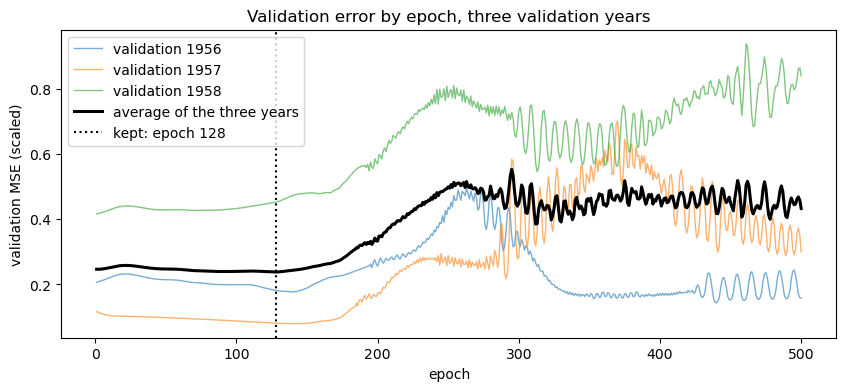

In [9]:
# Entrenamiento y pronóstico con semilla 0
f_lstm0, ep0, curves0 = fit_and_forecast(0, 'lstm')

results['LSTM (seed 0)'] = (
    rmse(f_lstm0, test),
    mape(f_lstm0, test)
)

print(f'epochs chosen on 1956–1958: {ep0}')

print(
    'LSTM (seed 0) RMSE %.1f MAPE %.1f%%'
    % results['LSTM (seed 0)']
)

# Curvas de validación
ep = np.arange(1, MAX_EPOCHS + 1)

for year, c in zip(VAL_YEARS, curves0):
    plt.plot(
        ep,
        c,
        lw=1,
        alpha=0.6,
        label=f'validation {year}'
    )

plt.plot(
    ep,
    curves0.mean(axis=0),
    'k',
    lw=2.2,
    label='average of the three years'
)

plt.axvline(
    ep0,
    color='k',
    ls=':',
    label=f'kept: epoch {ep0}'
)

plt.xlabel('epoch')
plt.ylabel('validation MSE (scaled)')
plt.legend()
plt.title('Validation error by epoch, three validation years')
plt.show()

### Interpretación de las curvas

En la ejecución mostrada en clase se seleccionaron **128 épocas**. Nuestro código imprime el valor obtenido en el entorno utilizado.

La época seleccionada minimiza el promedio de los errores de validación de los tres años. No necesariamente coincide con el mínimo de cada año por separado.

Si el error de validación aumenta mientras continúa el entrenamiento, puede indicar sobreajuste. La selección del número de épocas busca controlar este problema utilizando datos anteriores al periodo de prueba.

Después de elegir la época, el modelo se entrena nuevamente con todo el conjunto de entrenamiento. El RMSE y el MAPE impresos evalúan su pronóstico recursivo sobre 1959–1960.

Las curvas corresponden a validación a un paso, mientras que la evaluación final utiliza 24 pasos recursivos. Por ello, un buen resultado en estas curvas no garantiza un error bajo en el pronóstico final.

## 6. Comparación de LSTM y GRU con diez semillas

Evaluamos ambas arquitecturas utilizando **diez semillas diferentes**, de 0 a 9, para observar cuánto depende el resultado de la inicialización aleatoria.

En cada ejecución conservamos los mismos datos e hiperparámetros. El número de épocas se selecciona nuevamente mediante la validación temporal de 1956–1958.

Para cada arquitectura guardamos:

- Los 24 pronósticos de cada semilla.
- El RMSE individual.
- El número de épocas seleccionado.

Después combinamos los diez pronósticos mediante un promedio en escala logarítmica:

$$
\widehat{y}^{ens}_t=
\exp\left(
\frac{1}{10}\sum_{s=0}^{9}\ln(\widehat{y}^{(s)}_t)
\right)
$$

Esto equivale a una **media geométrica** de los pronósticos de cada mes. Evaluamos el ensamble con RMSE y MAPE.

El bloque realiza 20 ejecuciones completas y puede tardar varios minutos.

In [10]:
SEEDS = range(10)

runs, rmse_seed, epochs_seed = {}, {}, {}

for cell in ('lstm', 'gru'):
    # Entrenar, seleccionar épocas y pronosticar con cada semilla
    out = [
        fit_and_forecast(seed, cell)
        for seed in SEEDS
    ]

    # Pronósticos: 10 ejecuciones × 24 meses
    runs[cell] = np.array([
        o[0] for o in out
    ])

    # RMSE individual por semilla
    rmse_seed[cell] = [
        rmse(f, test) for f in runs[cell]
    ]

    # Épocas seleccionadas para cada semilla
    epochs_seed[cell] = [
        o[1] for o in out
    ]

    # Ensamble: promedio en escala logarítmica
    f_avg = np.exp(
        np.log(runs[cell]).mean(axis=0)
    )

    key = f'{cell.upper()}, average of 10 seeds'

    results[key] = (
        rmse(f_avg, test),
        mape(f_avg, test)
    )

    # Resumen de los errores individuales y del ensamble
    r = rmse_seed[cell]

    print(
        f'{cell.upper()}: RMSE over seeds '
        f'min {min(r):.1f}  '
        f'median {np.median(r):.1f}  '
        f'max {max(r):.1f}'
    )

    print(
        f'Ensemble: RMSE {results[key][0]:.1f}  '
        f'MAPE {results[key][1]:.1f}%'
    )

    print(f'Epochs: {epochs_seed[cell]}\n')

LSTM: RMSE over seeds min 81.1  median 88.7  max 112.0
Ensemble: RMSE 90.0  MAPE 17.7%
Epochs: [128, 152, 134, 134, 127, 75, 188, 101, 1, 112]

GRU: RMSE over seeds min 80.0  median 85.3  max 109.6
Ensemble: RMSE 88.0  MAPE 17.4%
Epochs: [90, 65, 66, 100, 83, 13, 71, 25, 98, 97]



## 6. Comparación de LSTM y GRU con diez semillas

Evaluamos ambas arquitecturas utilizando **diez semillas diferentes**, de 0 a 9, para observar cuánto depende el resultado de la inicialización aleatoria.

En cada ejecución conservamos los mismos datos e hiperparámetros. El número de épocas se selecciona nuevamente mediante la validación temporal de 1956–1958.

Para cada arquitectura guardamos:

- Los 24 pronósticos de cada semilla.
- El RMSE individual.
- El número de épocas seleccionado.

Después combinamos los diez pronósticos mediante un promedio en escala logarítmica:

$$
\widehat{y}^{ens}_t=
\exp\left(
\frac{1}{10}\sum_{s=0}^{9}\ln(\widehat{y}^{(s)}_t)
\right)
$$

Esto equivale a una **media geométrica** de los pronósticos de cada mes. Evaluamos el ensamble con RMSE y MAPE.

El bloque realiza 20 ejecuciones completas y puede tardar varios minutos.

In [11]:
SEEDS = range(10)

runs, rmse_seed, epochs_seed = {}, {}, {}

for cell in ('lstm', 'gru'):
    # Entrenar, seleccionar épocas y pronosticar con cada semilla
    out = [
        fit_and_forecast(seed, cell)
        for seed in SEEDS
    ]

    # Pronósticos: 10 ejecuciones × 24 meses
    runs[cell] = np.array([
        o[0] for o in out
    ])

    # RMSE individual por semilla
    rmse_seed[cell] = [
        rmse(f, test) for f in runs[cell]
    ]

    # Épocas seleccionadas para cada semilla
    epochs_seed[cell] = [
        o[1] for o in out
    ]

    # Ensamble: promedio en escala logarítmica
    f_avg = np.exp(
        np.log(runs[cell]).mean(axis=0)
    )

    key = f'{cell.upper()}, average of 10 seeds'

    results[key] = (
        rmse(f_avg, test),
        mape(f_avg, test)
    )

    # Resumen de los errores individuales y del ensamble
    r = rmse_seed[cell]

    print(
        f'{cell.upper()}: RMSE over seeds '
        f'min {min(r):.1f}  '
        f'median {np.median(r):.1f}  '
        f'max {max(r):.1f}'
    )

    print(
        f'Ensemble: RMSE {results[key][0]:.1f}  '
        f'MAPE {results[key][1]:.1f}%'
    )

    print(f'Epochs: {epochs_seed[cell]}\n')

LSTM: RMSE over seeds min 81.1  median 88.7  max 112.0
Ensemble: RMSE 90.0  MAPE 17.7%
Epochs: [128, 152, 134, 134, 127, 75, 188, 101, 1, 112]

GRU: RMSE over seeds min 80.0  median 85.3  max 109.6
Ensemble: RMSE 88.0  MAPE 17.4%
Epochs: [90, 65, 66, 100, 83, 13, 71, 25, 98, 97]



### Interpretación de los resultados

Para LSTM y GRU, la salida muestra el mínimo, la mediana y el máximo del RMSE entre las diez semillas. Una separación amplia indica mayor sensibilidad a la inicialización.

También se muestran las métricas del ensamble y las épocas seleccionadas para cada ejecución. Las épocas pueden variar porque cada inicialización produce curvas de validación diferentes.

El ensamble busca reducir la dependencia de una sola ejecución, pero no garantiza superar al mejor modelo individual ni a las referencias anteriores.

La mediana de los RMSE individuales y el RMSE del ensamble son medidas distintas: el segundo se calcula después de combinar los pronósticos.

Para comparar las arquitecturas, revisaremos tanto sus errores como su variabilidad. No elegiremos la mejor semilla a partir del periodo de prueba, porque eso sesgaría la evaluación.

## 9. Comparación visual de los pronósticos

Graficamos los pronósticos de 1959–1960 junto con los valores reales:

- **Líneas azules transparentes:** las diez ejecuciones individuales de la LSTM.
- **Línea azul gruesa:** ensamble de las diez LSTM.
- **Línea verde:** ensamble de las diez MLP.
- **Línea naranja:** regresión lineal AR(13).
- **Línea negra:** pasajeros observados.

El ensamble LSTM se calcula mediante el promedio de los logaritmos de sus pronósticos y su posterior exponenciación.

Todos los pronósticos parten de diciembre de 1958 y cubren 24 meses sin incorporar las observaciones reales del periodo de prueba.

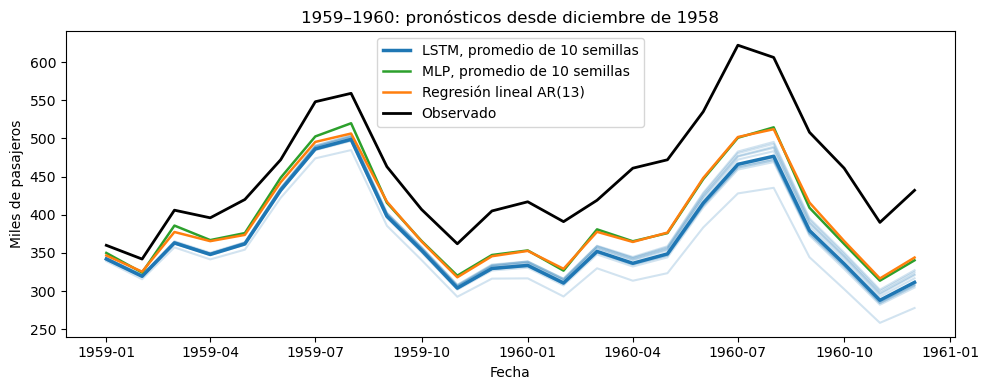

In [13]:
from sklearn.neural_network import MLPRegressor

# Calcular los pronósticos MLP solamente si faltan
if 'mlp' not in runs:
    def mlp_forecast(seed):
        net = MLPRegressor(
            hidden_layer_sizes=(32,),
            activation='relu',
            alpha=1e-3,
            max_iter=5000,
            random_state=seed
        )
        net.fit(Xz, tz)

        zf = recursive_forecast(
            net, (ztr - mz) / sz, p, H
        ) * sz + mz

        return np.exp(undo(zf, Ltr))

    runs['mlp'] = np.array([
        mlp_forecast(seed) for seed in range(10)
    ])

# Construir ambos ensambles
f_mlp_avg = np.exp(np.log(runs['mlp']).mean(axis=0))
f_lstm_avg = np.exp(np.log(runs['lstm']).mean(axis=0))

results['MLP, average of 10 seeds'] = (
    rmse(f_mlp_avg, test),
    mape(f_mlp_avg, test)
)

# Crear una figura nueva
plt.figure(figsize=(10, 4))

plt.plot(
    test.index, runs['lstm'].T,
    color='C0', alpha=0.2
)

plt.plot(
    test.index, f_lstm_avg, 'C0',
    lw=2.5, label='LSTM, promedio de 10 semillas'
)

plt.plot(
    test.index, f_mlp_avg, 'C2',
    lw=1.8, label='MLP, promedio de 10 semillas'
)

plt.plot(
    test.index, f_lin, 'C1',
    lw=1.8, label='Regresión lineal AR(13)'
)

plt.plot(
    test.index, test, 'k',
    lw=2, label='Observado'
)

plt.xlabel('Fecha')
plt.ylabel('Miles de pasajeros')
plt.legend()
plt.title('1959–1960: pronósticos desde diciembre de 1958')
plt.tight_layout()
plt.show()

### Interpretación de la gráfica

La gráfica permite comparar qué tan bien cada modelo reproduce el nivel de pasajeros y los aumentos y disminuciones estacionales.

La separación entre las líneas individuales de la LSTM muestra la variabilidad de sus pronósticos al cambiar la semilla. Esta dispersión **no es un intervalo de predicción**: representa únicamente diferencias entre ejecuciones.

Las distancias respecto a la línea negra muestran los errores de cada mes. Conviene revisar especialmente los máximos estacionales y si algún modelo sobreestima o subestima de manera persistente.

La evaluación visual complementa el RMSE y el MAPE de la tabla. Para identificar el mejor desempeño en este periodo, debemos considerar ambas métricas junto con el comportamiento de los pronósticos.